# 04 · Model experiments
Results of nested, patient-grouped CV (5 outer folds × 3 repeats; 4 inner grouped folds).

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
from oncogene.config import Paths, load_config
from oncogene.data.load import load_processed
paths, cfg = Paths(), load_config()
ds = load_processed(paths)
X, meta, ann = ds.X, ds.meta, ds.annotation
M = paths.metrics
print(X.shape, meta.shape)

(50, 17868) (50, 9)


In [2]:
s = json.loads((M/'model_summary.json').read_text())
pd.DataFrame({m: {k: f"{v['mean']:.3f} ± {v['sd']:.3f}" for k, v in d['fold'].items()} for m, d in s['models'].items()}).T

,accuracy,precision,recall,specificity,f1,balanced_accuracy,roc_auc
dummy,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.500 ± 0.000
logistic_regression,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
random_forest,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
svm,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000


In [3]:
pd.DataFrame({m: d['patient_level_exact_ci'] for m, d in s['models'].items()}).T

,patients_fully_correct,n_patients,proportion,ci95,max_plausible_patient_error_rate
dummy,0,25,0.0,"[0.0, 0.13718517153071252]",1.0
logistic_regression,25,25,1.0,"[0.8628148284692875, 1.0]",0.137185
random_forest,25,25,1.0,"[0.8628148284692875, 1.0]",0.137185
svm,25,25,1.0,"[0.8628148284692875, 1.0]",0.137185


In [4]:
p = pd.read_csv(M/'fold_best_params.csv'); p.groupby('model')[['n_grid_points','n_tied_at_best']].mean()

,n_grid_points,n_tied_at_best
model,,
dummy,1.0,NaN
logistic_regression,6.0,6.0
random_forest,16.0,16.0
svm,10.0,10.0


Ties at the best inner score mean hyperparameter 'selection' is mostly arbitrary for this easy task.

In [5]:
lc = pd.read_csv(M/'learning_curve.csv')
g = lc.groupby('n_train_patients')[['roc_auc','balanced_accuracy']].agg(['mean','std','min']); g

roc_auc                     balanced_accuracy            \
                      mean       std       min              mean       std   
n_train_patients                                                             
1                 0.982812  0.027185  0.880208          0.838889  0.098925   
2                 0.997984  0.003215  0.988658          0.935507  0.069566   
3                 0.999380  0.001812  0.991736          0.968182  0.051895   
4                 0.999395  0.001780  0.990930          0.988889  0.020485   
6                 0.999631  0.001406  0.994460          0.994737  0.014496   
8                 0.999654  0.001056  0.996540          0.994118  0.016202   
12                1.000000  0.000000  1.000000          1.000000  0.000000   
16                1.000000  0.000000  1.000000          1.000000  0.000000   
20                1.000000  0.000000  1.000000          1.000000  0.000000   

                            
                       min  
n_train_patients            
1                 0.625000  
2                 0.739130  
3                 0.772727  
4                 0.928571  
6                 0.947368  
8                 0.941176  
12                1.000000  
16                1.000000  
20                1.000000

(0.3, 1.05)

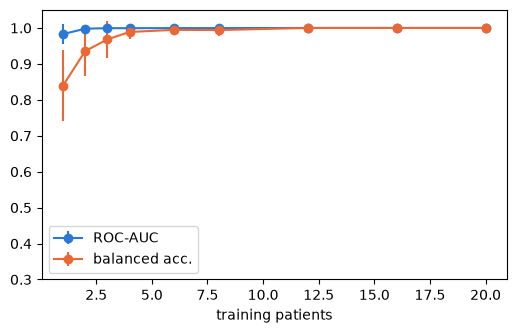

In [6]:
fig, ax = plt.subplots(figsize=(6,3.5))
ax.errorbar(g.index, g[('roc_auc','mean')], g[('roc_auc','std')], marker='o', color='#2a78d6', label='ROC-AUC')
ax.errorbar(g.index, g[('balanced_accuracy','mean')], g[('balanced_accuracy','std')], marker='o', color='#eb6834', label='balanced acc.')
ax.set_xlabel('training patients'); ax.legend(); ax.set_ylim(0.3, 1.05)

## Re-running a single model (optional, ~1–2 min)

In [7]:
# from oncogene.models.evaluate import run_nested_cv
# res = run_nested_cv('logistic_regression', X, ds.y, ds.groups, cfg, compute_permutation=False)
# res.summary['fold']['roc_auc']